<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_Explainable_AI_SHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGCB — explainable forecasting with SHAP

**Research title:** *An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids*

This notebook adds **explainable AI (XAI)** to the Ridge day-ahead forecasting component chosen in Phase 2. It is a separate analysis; it **does not change the optimizer** developed in Phases 3–5.

**Research objective:** Describe which historical-demand and calendar features contribute most to the selected Ridge model's forecast, and explain a representative individual prediction. Generate high-resolution SHAP figures ready for inclusion in the *Results and Analysis* section of an IEEE manuscript.

**Source data:** PGCB Hourly Generation Dataset (Bangladesh), UCI dataset 1175, [DOI: 10.24432/C59P6V](https://doi.org/10.24432/C59P6V) (CC BY 4.0). [UCI page](https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset+(bangladesh)).

**SHAP reference:** S. M. Lundberg and S.-I. Lee, [*A Unified Approach to Interpreting Model Predictions*](https://proceedings.neurips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html), NeurIPS 2017. [Official SHAP documentation](https://shap.readthedocs.io/en/stable/).

**Interpretation boundaries:** SHAP explains the fitted **forecasting model**, not causation, electrical-grid physics, or the optimization algorithm's decisions. Highly correlated lagged-demand features can redistribute importance between one another. These are exploratory explanations of 2023 data already examined in earlier research phases.

## 1. Software requirements

We use `scikit-learn` for the original Ridge pipeline and SHAP's linear explainer for additive feature attribution. The installation step runs only when SHAP is missing. A standard Colab CPU runtime is sufficient.

In [ ]:
import sys
import subprocess
import importlib.util

if importlib.util.find_spec('shap') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shap>=0.47,<0.52', '-q'])

import hashlib
import io
import json
import os
import platform
import shutil
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shap
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
IS_COLAB = 'google.colab' in sys.modules
print('Runtime:', 'Colab' if IS_COLAB else 'local Python')
print('Python:', platform.python_version())
print('shap:', shap.__version__, '| sklearn:', sklearn.__version__)

Runtime: Colab
Python: 3.13.16
shap: 0.54.1 | sklearn: 1.6.1


## 2. Experiment configuration and output location

The working directory is the same as in Phases 1–5. Each run is stored in a new timestamped folder so earlier experiments are never overwritten. Set `USE_GOOGLE_DRIVE=False` only if you deliberately want runtime-only outputs.

In [ ]:
USE_GOOGLE_DRIVE = True
DATASET_FILENAME = 'PGCB_date_power_demand.xlsx'
UCI_ARCHIVE_URL = (
    'https://archive.ics.uci.edu/static/public/1175/'
    'pgcb%2Bhourly%2Bgeneration%2Bdataset%2B%28bangladesh%29.zip'
)
DEMAND_SCREEN = (1000.0, 30000.0)
GENERATION_SCREEN = (0.0, 30000.0)
BACKGROUND_SIZE = 256
SAMPLES_PER_MONTH = 60

if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    PROJECT = Path('/content/PGCB_Demand_Optimization')
else:
    PROJECT = Path('/mnt/data/PGCB_Demand_Optimization')

DATA_DIR = PROJECT / 'data'
RUN_ID = 'xai_shap_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
OUTPUT = PROJECT / 'runs' / RUN_ID
FIGURES = OUTPUT / 'figures'
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=False)
FIGURES.mkdir(parents=True, exist_ok=False)
print('Run:', RUN_ID)
print('Output:', OUTPUT)

Mounted at /content/drive
Run: xai_shap_20261108T030802Z_56d539
Output: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/xai_shap_20261108T030802Z_56d539


## 3. Load and fingerprint the UCI dataset

We reuse the original Excel workbook already cached in Google Drive, or retrieve it from UCI on the first run. The original data is not altered. A SHA-256 fingerprint helps reviewers verify the precise version used.

In [ ]:
DATA_PATH = DATA_DIR / DATASET_FILENAME
local_override = os.environ.get('PGCB_LOCAL_XLSX') if not IS_COLAB else None
if local_override:
    DATA_PATH = Path(local_override)

if not DATA_PATH.exists():
    print('Downloading the original dataset from UCI...')
    response = requests.get(UCI_ARCHIVE_URL, timeout=180)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as zf:
        candidates = [n for n in zf.namelist() if n.lower().endswith(DATASET_FILENAME.lower())]
        if len(candidates) != 1:
            raise RuntimeError('Unable to identify a unique workbook in the UCI archive.')
        partial = DATA_DIR / (DATASET_FILENAME + '.partial')
        try:
            with zf.open(candidates[0]) as src, partial.open('wb') as dest:
                shutil.copyfileobj(src, dest)
            partial.replace(DATA_PATH)
        finally:
            partial.unlink(missing_ok=True)

source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_excel(
    DATA_PATH, engine='openpyxl',
    usecols=['datetime', 'demand_mw', 'generation_mw', 'load_shedding'],
)
assert {'datetime','demand_mw','generation_mw','load_shedding'}.issubset(raw.columns)
print('Rows:', len(raw), '| source SHA-256:', source_sha256)

Rows: 92650 | source SHA-256: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1


## 4. Replicate the Phase 2 chronological cleaning protocol

We keep unique, on-the-hour records with plausible demand and generation values and require complete 24-hour days. The broad numeric screens are exploratory data-quality filters, not actual generator ratings. For this explainability study, records after 2023 are excluded entirely.

In [ ]:
work = raw.copy()
work['datetime'] = pd.to_datetime(work['datetime'], errors='coerce')
for col in ('demand_mw','generation_mw','load_shedding'):
    work[col] = pd.to_numeric(work[col], errors='coerce')

scope = work.loc[work['datetime'] < pd.Timestamp('2024-01-01')].copy()
duplicates = scope['datetime'].duplicated(keep=False)
valid = (
    scope['datetime'].dt.minute.eq(0)
    & scope['datetime'].dt.second.eq(0)
    & ~duplicates
    & scope['demand_mw'].between(*DEMAND_SCREEN)
    & scope['generation_mw'].between(*GENERATION_SCREEN)
)
hourly = scope.loc[valid, ['datetime','demand_mw']].sort_values('datetime').set_index('datetime')
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
counts = hourly.groupby(hourly.index.normalize()).size()
complete_days = counts[counts.eq(24)].index
complete = hourly.loc[hourly.index.normalize().isin(complete_days)].copy()
print('Eligible complete days before feature checks:', len(complete_days))
print('Records retained:', len(complete))

Eligible complete days before feature checks: 2684
Records retained: 64416


## 5. Reconstruct the original day-ahead forecasting features

To avoid changing the forecasting method, we use the **same 14 variables** as Phase 2: five historical-demand lags, two derived demand statistics, and seven calendar indicators. All lagged demand values come from previous days, never from the target day.

In [ ]:
frame = complete.rename(columns={'demand_mw':'actual_mw'}).copy()
for days_back in (1, 2, 3, 7, 14):
    prior = frame.index - pd.Timedelta(days=days_back)
    frame[f'lag_{days_back}d_mw'] = complete['demand_mw'].reindex(prior).to_numpy()
frame = frame.loc[frame['lag_1d_mw'].notna() & frame['lag_7d_mw'].notna()].copy()
frame['date'] = frame.index.normalize()
frame['hour'] = frame.index.hour
frame['day_of_week'] = frame.index.dayofweek
frame['day_of_year'] = frame.index.dayofyear
frame['weekend'] = (frame['day_of_week'] >= 5).astype(int)

for label, value, cycle in (
    ('hour',frame['hour'],24),
    ('weekday',frame['day_of_week'],7),
    ('year',frame['day_of_year'],365.25),
):
    frame[f'{label}_sin'] = np.sin(2 * np.pi * value / cycle)
    frame[f'{label}_cos'] = np.cos(2 * np.pi * value / cycle)

frame['yesterday_vs_week_mw'] = frame['lag_1d_mw'] - frame['lag_7d_mw']
frame['last_three_days_mean_mw'] = frame[
    ['lag_1d_mw','lag_2d_mw','lag_3d_mw']
].mean(axis=1)

FEATURES = [
    'lag_1d_mw','lag_2d_mw','lag_3d_mw','lag_7d_mw','lag_14d_mw',
    'yesterday_vs_week_mw','last_three_days_mean_mw',
    'hour_sin','hour_cos','weekday_sin','weekday_cos',
    'year_sin','year_cos','weekend',
]
DISPLAY_NAMES = [
    'Previous day (MW)','2 days earlier (MW)','3 days earlier (MW)',
    'Previous week (MW)','2 weeks earlier (MW)',
    'Day–week difference (MW)','Previous 3-day mean (MW)',
    'Hour sine','Hour cosine','Weekday sine','Weekday cosine',
    'Annual sine','Annual cosine','Weekend',
]
assert frame.groupby('date').size().eq(24).all()
assert not frame[FEATURES].isna().all(axis=1).any()
print('Feature count:',len(FEATURES),'| Modeling hours:',len(frame))

Feature count: 14 | Modeling hours: 48312


## 6. Refit the selected Ridge model without changing its configuration

Phase 2 selected Ridge regression on early-2022 validation data and refitted it through **June 30, 2022**. We reproduce that fitted model with median imputation, standard scaling and `Ridge(alpha=100)`. The model is **not retrained on 2023**, which is the period used to illustrate SHAP explanations.

In [ ]:
training = frame.loc[frame['date'] < '2022-07-01'].copy()
calibration = frame.loc[(frame['date'] >= '2022-07-01') & (frame['date'] < '2023-01-01')].copy()
evaluation = frame.loc[(frame['date'] >= '2023-01-01') & (frame['date'] < '2024-01-01')].copy()
assert len(training) > 100 and len(calibration) > 100 and len(evaluation) > 100

model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    Ridge(alpha=100.0),
)
model.fit(training[FEATURES], training['actual_mw'])
evaluation_pred = model.predict(evaluation[FEATURES])
mae_2023 = float(mean_absolute_error(evaluation['actual_mw'],evaluation_pred))
assert abs(mae_2023 - 614.3212742401635) < 1.0, (
    'The Phase 2 MAE was not reproduced. Check dataset hash, filtering, sklearn, and features.'
)
print('Refitted model: Ridge(alpha=100)')
print('2023 eligible days:',evaluation['date'].nunique())
print('2023 MAE (MW):',round(mae_2023,3))

Refitted model: Ridge(alpha=100)
2023 eligible days: 274
2023 MAE (MW): 614.321


## 7. Select representative evaluation hours and a training-only background

We sample up to **60 hours per calendar month** from 2023 using a fixed random seed, rather than choosing hours that make a figure look favorable. The explainer's background uses only observations from the model's training period. This avoids using the 2023 target period to set the SHAP reference distribution.

In [ ]:
rng = np.random.default_rng(SEED)
selected_positions = []
for month, group in evaluation.groupby(evaluation.index.month, sort=True):
    positions = np.flatnonzero(evaluation.index.month == month)
    n_take = min(SAMPLES_PER_MONTH, len(positions))
    selected_positions.extend(rng.choice(positions, size=n_take, replace=False).tolist())
selected_positions = np.asarray(sorted(selected_positions),dtype=int)
selected = evaluation.iloc[selected_positions].copy()

bg_positions = np.linspace(0,len(training)-1, num=min(BACKGROUND_SIZE,len(training)),dtype=int)
X_background = training.iloc[bg_positions][FEATURES]
X_selected = selected[FEATURES]

imputer = model.named_steps['simpleimputer']
scaler = model.named_steps['standardscaler']
regressor = model.named_steps['ridge']

# Explain the linear model in standardized space, then display original units.
Z_background = scaler.transform(imputer.transform(X_background))
Z_selected = scaler.transform(imputer.transform(X_selected))
raw_display = imputer.transform(X_selected)
print('SHAP background hours:',len(X_background),'(training only)')
print('Explained 2023 hours:',len(X_selected),'across',selected.index.month.nunique(),'months')

SHAP background hours: 256 (training only)
Explained 2023 hours: 720 across 12 months


## 8. Compute SHAP values and validate the additive explanation

SHAP assigns each input a contribution to the **forecast in MW** relative to a training-period reference prediction. We use an independent-feature masker, which makes the reference explicit and computation efficient for Ridge. The lags are correlated, so individual attribution sizes should not be read as causal effects.

In [ ]:
masker = shap.maskers.Independent(Z_background, max_samples=len(Z_background))
explainer = shap.LinearExplainer(regressor, masker)
transformed_explanation = explainer(Z_selected)
shap_values = shap.Explanation(
    values=np.asarray(transformed_explanation.values),
    base_values=np.asarray(transformed_explanation.base_values),
    data=raw_display,
    feature_names=DISPLAY_NAMES,
)
selected_prediction = model.predict(X_selected)
shap_reconstructed = np.asarray(shap_values.base_values) + np.asarray(shap_values.values).sum(axis=1)
max_additivity_gap_mw = float(np.max(np.abs(selected_prediction-shap_reconstructed)))
assert max_additivity_gap_mw < 1e-5, f'SHAP additivity check failed: {max_additivity_gap_mw:.5f} MW'
print('Max SHAP reconstruction gap (MW):',max_additivity_gap_mw)
print('Output unit of SHAP values: MW')

Max SHAP reconstruction gap (MW): 3.637978807091713e-12
Output unit of SHAP values: MW


## 9. Global feature importance and numerical attribution tables

We rank features by their **mean absolute SHAP magnitude** across the fixed 2023 sample. This tells us how much a feature tends to move the fitted Ridge model's output, not how important the feature is to the power grid itself. An additional grouped table summarizes historical-load versus calendar attributions.

In [ ]:
abs_mean = np.abs(shap_values.values).mean(axis=0)
importance = pd.DataFrame({
    'feature': FEATURES,
    'display_name': DISPLAY_NAMES,
    'mean_abs_shap_mw': abs_mean,
}).sort_values('mean_abs_shap_mw',ascending=False)
importance.to_csv(OUTPUT/'shap_global_importance_2023.csv',index=False)
print(importance.round(2).to_string(index=False))

full_sample = pd.DataFrame(shap_values.values, columns=FEATURES, index=selected.index)
full_sample.insert(0,'predicted_demand_mw',selected_prediction)
full_sample.insert(0,'actual_demand_mw',selected['actual_mw'].to_numpy())
full_sample.insert(0,'datetime',selected.index)
full_sample.to_csv(OUTPUT/'shap_hourly_sample_2023.csv',index=False)

groups = {
    'Historical demand': FEATURES[:7],
    'Calendar and seasonality': FEATURES[7:],
}
group_importance = pd.DataFrame([
    {'feature_group':name, 'mean_abs_group_shap_mw':float(np.abs(full_sample[cols].sum(axis=1)).mean()),
     'sum_individual_mean_abs_shap_mw':float(np.abs(full_sample[cols]).mean().sum())}
    for name,cols in groups.items()
])
group_importance.to_csv(OUTPUT/'shap_group_importance_2023.csv',index=False)

                feature             display_name  mean_abs_shap_mw
              lag_1d_mw        Previous day (MW)           1035.49
              lag_7d_mw       Previous week (MW)            895.36
last_three_days_mean_mw Previous 3-day mean (MW)            587.34
                weekend                  Weekend            215.23
   yesterday_vs_week_mw Day–week difference (MW)            188.83
             lag_14d_mw     2 weeks earlier (MW)            170.33
            weekday_sin             Weekday sine            147.85
              lag_2d_mw      2 days earlier (MW)            118.81
            weekday_cos           Weekday cosine             85.34
               year_sin              Annual sine             32.50
               year_cos            Annual cosine             29.74
               hour_sin                Hour sine             19.14
              lag_3d_mw      3 days earlier (MW)              8.50
               hour_cos              Hour cosine              

## 10. Figure A — Global SHAP bar chart

**Manuscript placement:** *Results and Analysis → Explainable AI (SHAP)*. Bars indicate the model's average absolute feature contribution in MW. Files are saved as 300-dpi PNG and vector PDF.

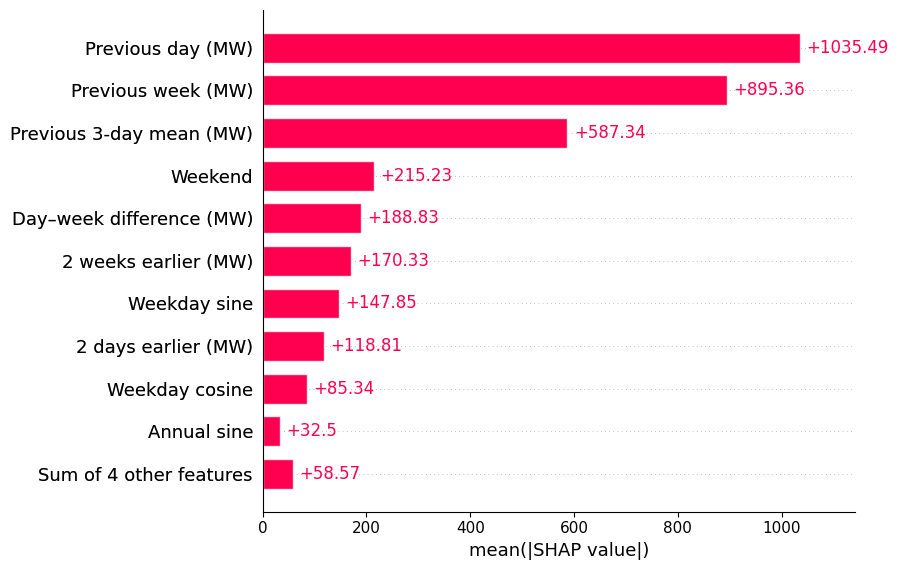

In [ ]:
plt.close('all')
shap.plots.bar(shap_values, max_display=11, show=False)
fig = plt.gcf()
fig.set_size_inches(9,5.8)
fig.tight_layout()
fig.savefig(FIGURES/'figure_shap_global_bar.png',dpi=600,bbox_inches='tight')
fig.savefig(FIGURES/'figure_shap_global_bar.pdf',bbox_inches='tight')
plt.show()
plt.close('all')

## 11. Figure B — SHAP beeswarm distribution

**Manuscript placement:** Beside or after Figure A. Each point represents one sampled hour; the horizontal coordinate is the SHAP contribution (MW). The color identifies relatively high or low feature values, not whether a model prediction was correct.

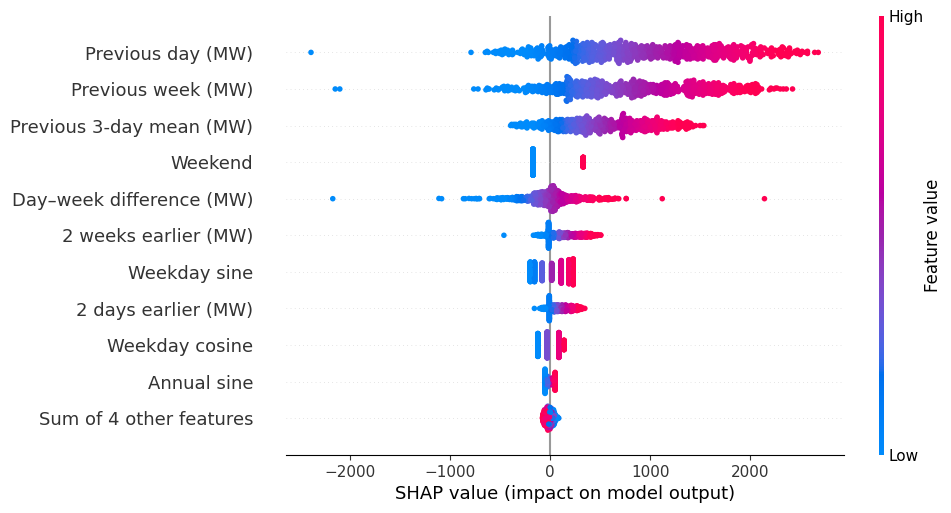

In [ ]:
plt.close('all')
shap.plots.beeswarm(shap_values, max_display=11, show=False, plot_size=(9,5.7))
fig = plt.gcf()
fig.savefig(FIGURES/'figure_shap_beeswarm.png',dpi=600,bbox_inches='tight')
fig.savefig(FIGURES/'figure_shap_beeswarm.pdf',bbox_inches='tight')
plt.show()
plt.close('all')

## 12. Figure C — Feature-value versus SHAP contribution

We plot the feature ranked first in the global importance table. This illustrates how its value changes its contribution to the **Ridge forecast**, conditional on the explainer's background definition. For linear models with independent masking, this often appears approximately linear; it should not be interpreted as a physical response curve.

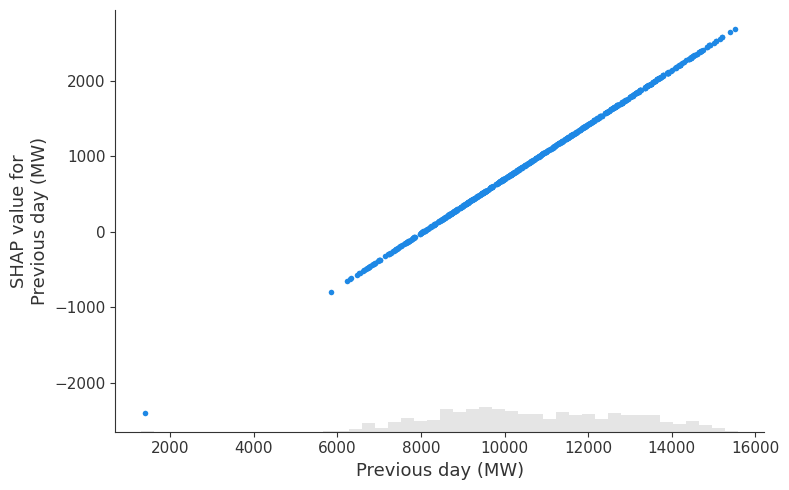

Top global feature: lag_1d_mw


In [ ]:
top_feature = str(importance.iloc[0]['feature'])
top_feature_index = FEATURES.index(top_feature)
plt.close('all')
shap.plots.scatter(shap_values[:,top_feature_index],show=False)
fig = plt.gcf()
fig.set_size_inches(8,5)
fig.tight_layout()
fig.savefig(FIGURES/'figure_shap_top_feature_effect.png',dpi=600,bbox_inches='tight')
fig.savefig(FIGURES/'figure_shap_top_feature_effect.pdf',bbox_inches='tight')
plt.show()
plt.close('all')
print('Top global feature:',top_feature)

## 13. Figure D — One transparently selected local SHAP explanation

We choose the **first eligible 18:00 hour in July 2023** using a rule specified in the notebook, rather than selecting a visually impressive case. The waterfall figure shows how the 14 features move this specific forecast above or below the background reference. We include the recorded demand for context, but the SHAP values explain the prediction, not the prediction error.

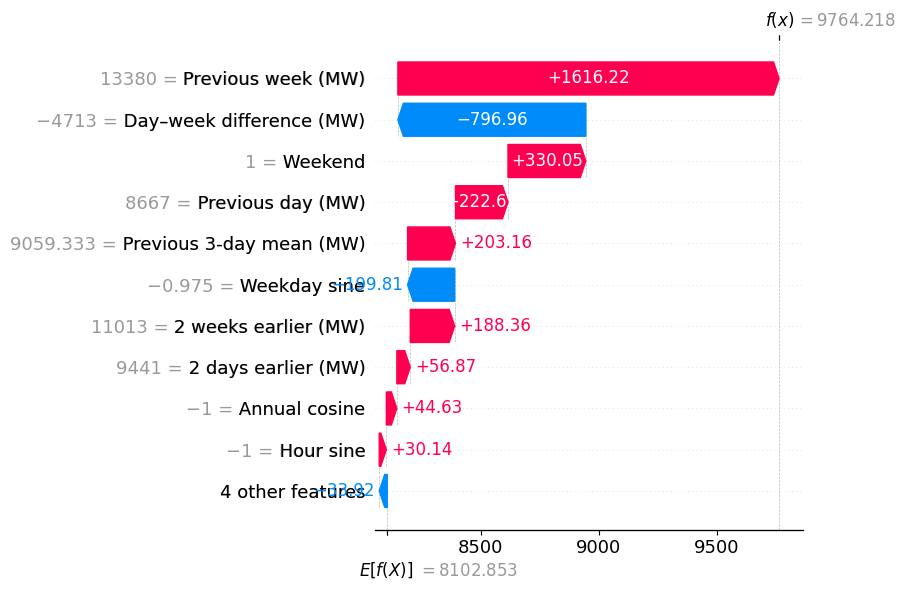

{'selection_rule': 'First eligible July 2023 hour equal to 18:00', 'datetime': '2023-07-01 18:00:00', 'actual_demand_mw': 9308.0, 'predicted_demand_mw': 9764.21827890487, 'reference_prediction_mw': 8102.852518296884, 'reconstruction_error_mw': 0.0}


In [ ]:
local_candidates = evaluation.loc[
    (evaluation.index.month == 7) & (evaluation.index.hour == 18)
]
if local_candidates.empty:
    raise RuntimeError('No eligible July 18:00 hour; choose a predeclared alternative date rule.')
local = local_candidates.iloc[[0]].copy()
Z_local = scaler.transform(imputer.transform(local[FEATURES]))
raw_local = imputer.transform(local[FEATURES])
local_transformed = explainer(Z_local)
local_explanation = shap.Explanation(
    values=np.asarray(local_transformed.values),
    base_values=np.asarray(local_transformed.base_values),
    data=raw_local,
    feature_names=DISPLAY_NAMES,
)
local_prediction = float(model.predict(local[FEATURES])[0])
local_reconstructed = float(local_explanation.base_values[0] + local_explanation.values[0].sum())
assert abs(local_prediction-local_reconstructed)<1e-5

plt.close('all')
shap.plots.waterfall(local_explanation[0], max_display=11,show=False)
fig = plt.gcf()
fig.set_size_inches(9,6)
fig.tight_layout()
fig.savefig(FIGURES/'figure_shap_local_waterfall.png',dpi=600,bbox_inches='tight')
fig.savefig(FIGURES/'figure_shap_local_waterfall.pdf',bbox_inches='tight')
plt.show()
plt.close('all')

local_details = {
    'selection_rule':'First eligible July 2023 hour equal to 18:00',
    'datetime':str(local.index[0]),
    'actual_demand_mw':float(local['actual_mw'].iloc[0]),
    'predicted_demand_mw':local_prediction,
    'reference_prediction_mw':float(local_explanation.base_values[0]),
    'reconstruction_error_mw':abs(local_prediction-local_reconstructed),
}
(OUTPUT/'shap_local_case_2023.json').write_text(json.dumps(local_details,indent=2))
print(local_details)

## 14. Save figure captions and reproducibility metadata

The caption file gives a journal-style description for each figure without overstating what SHAP establishes. The manifest records model details, data dates, package versions, and source checksum. We also save a ZIP containing the figures and tables for easy backup, manuscript preparation, and GitHub documentation.

In [ ]:
top_name = str(importance.iloc[0]['display_name'])
captions = f"""# SHAP figure captions — PGCB demand forecasting

**Figure A (figure_shap_global_bar):** Mean absolute SHAP feature attributions (MW) for the selected Ridge day-ahead demand forecasting model, computed from {len(selected)} stratified-sampled hourly observations in 2023 using a training-only background of {len(X_background)} observations. The strongest feature in this sample was {top_name}. Rankings characterize the fitted model, not causal effects.

**Figure B (figure_shap_beeswarm):** Distribution of SHAP contributions (MW) across the sampled 2023 evaluation hours. Positive and negative values indicate directions of model contribution relative to the training-period reference forecast; feature colors indicate relative observed values.

**Figure C (figure_shap_top_feature_effect):** Dependence of the SHAP contribution on {top_name}, the largest mean-absolute attribution in the selected sample. Associations pertain to the fitted forecasting model and do not establish physical causation.

**Figure D (figure_shap_local_waterfall):** Local SHAP decomposition of the predicted demand at {local.index[0]}, chosen in advance as the first eligible July 18:00 observation. Baseline and feature contributions sum to the predicted demand in MW.

**Method note:** Ridge(alpha=100) with median imputation and standard scaling was fitted on records through June 2022; figures explain evaluated 2023 inputs. SHAP used the independent-feature masker on standardized input values and a training-only background. Correlated lagged demand inputs can share or redistribute attributed importance. The method explains the *forecast*, not the downstream demand-scheduling optimizer or avoided load shedding.

**Reference:** S. M. Lundberg and S.-I. Lee, "A Unified Approach to Interpreting Model Predictions," *Advances in Neural Information Processing Systems*, vol. 30, 2017. https://proceedings.neurips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html
"""
(OUTPUT/'SHAP_figure_captions.md').write_text(captions,encoding='utf-8')

manifest = {
    'project_title':'An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids',
    'phase':'Explainability of Phase 2 demand forecasts using SHAP',
    'run_id':RUN_ID,
    'dataset':{'doi':'10.24432/C59P6V','file':DATA_PATH.name,'sha256':source_sha256},
    'forecast_model':'Median imputation + StandardScaler + Ridge(alpha=100)',
    'fit_through':'2022-06-30',
    'evaluation_period':'2023-01-01 to 2023-12-31',
    'evaluated_days':int(evaluation['date'].nunique()),
    'evaluation_mae_mw':mae_2023,
    'explained_hours':len(selected),
    'samples_per_calendar_month':SAMPLES_PER_MONTH,
    'background_hours':len(X_background),
    'background_source':'Fitted training period only, uniformly spaced sample',
    'attribution_method':'shap.LinearExplainer + shap.maskers.Independent on standardized Ridge inputs',
    'max_additivity_error_mw':max_additivity_gap_mw,
    'top_feature':top_feature,
    'local_example':local_details,
    'feature_names':FEATURES,
    'software':{'python':platform.python_version(),'numpy':np.__version__,
                'pandas':pd.__version__,'sklearn':sklearn.__version__,'shap':shap.__version__},
    'limitations':[
        'Explains Ridge forecasts, not the scheduling optimizer or causal grid effects.',
        'Lagged input correlation affects interpretation of individual SHAP values.',
        'The 2023 evaluation period has been examined in previous phases and is exploratory.',
        'Full-day screen excludes irregular/duplicate records; attribution population is restricted.',
        'No measured actual load-shedding mitigation is supported by SHAP figures.'
    ],
}
(OUTPUT/'shap_protocol.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')

archive_name = OUTPUT/'shap_outputs.zip'
with zipfile.ZipFile(archive_name,'w',zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(OUTPUT.rglob('*')):
        if p.is_file() and p != archive_name:
            zf.write(p,arcname=str(p.relative_to(OUTPUT)))
assert all((FIGURES/f'{stem}.{ext}').is_file() for stem in (
    'figure_shap_global_bar','figure_shap_beeswarm',
    'figure_shap_top_feature_effect','figure_shap_local_waterfall'
) for ext in ('png','pdf'))
print('SHAP analysis finished. Files:',sorted(p.name for p in OUTPUT.iterdir()))
print('Figures:',FIGURES)
print('The images can be inserted into the IEEE manuscript after caption review.')

SHAP analysis finished. Files: ['SHAP_figure_captions.md', 'figures', 'shap_global_importance_2023.csv', 'shap_group_importance_2023.csv', 'shap_hourly_sample_2023.csv', 'shap_local_case_2023.json', 'shap_outputs.zip', 'shap_protocol.json']
Figures: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/xai_shap_20261108T030802Z_56d539/figures
The images can be inserted into the IEEE manuscript after caption review.
